# 4.5.1 Arbitrer seulement les cas les plus durs (top1 contre top2) : Dataset 2 (1er extrait)

Quand le SVM texte hésite entre ses deux premières classes, un second signal tranche. Trois arbitres
sur les mêmes documents incertains : le LLM (avec seulement les 2 classes dans le prompt), la position
des mots et la détection de tableau. Même échantillon OCR qu'en 4.2 (1 800 documents, 360 en test).

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import ollama
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.svm import LinearSVC

from outils_4 import ARTEFACTS_30K, load_ocr_sample, top_two, classify_by_cosine, table_features

train_df, test_df = load_ocr_sample()
y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

## 1. Le SVM et ses documents incertains

SVM sur TF-IDF caractères, C = 1 (choisi en 4.2).

In [2]:
vectoriseur = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
svm = LinearSVC(C=1, random_state=42, max_iter=5000).fit(vectoriseur.fit_transform(train_df["text"]), y_train)
candidats = top_two(svm.decision_function(vectoriseur.transform(test_df["text"])), svm.classes_)

prediction_svm = candidats["top1"].to_numpy()
svm_juste = prediction_svm == y_test
zone = (candidats["ecart"] < 0.3).to_numpy()
dans_top2 = svm_juste | (candidats["top2"] == y_test).to_numpy()

print(f"Accuracy du SVM : {svm_juste.mean():.1%}")
print(f"Documents incertains (écart < 0,3) : {zone.sum()}, accuracy du SVM sur eux : {svm_juste[zone].mean():.1%}")
print(f"Au mieux, un arbitre top1/top2 peut en avoir juste {dans_top2[zone].sum()}/{zone.sum()} "
      f"(pour les autres, la bonne classe n'est ni 1re ni 2e)")

Accuracy du SVM : 86.9%
Documents incertains (écart < 0,3) : 67 : accuracy du SVM sur eux : 56.7%
Au mieux, un arbitre top1/top2 peut en avoir juste 56/67 (pour les autres, la bonne classe n'est ni 1re ni 2e)


## 2. Les trois arbitres

LLM : les réponses sont relues dans un cache, les nouvelles questions sont posées à Ollama.

In [3]:
def arbitrate_with_llm(chemin, classe_a, classe_b):
    """le LLM choisit entre les 2 classes (classe_a s'il répond autre chose)"""
    prompt = (f"Voici un document scanné. Il s'agit soit d'un document de type '{classe_a}', "
              f"soit de type '{classe_b}'. Lequel des deux est-ce le plus probablement ? "
              "Réponds uniquement par le nom exact de la catégorie choisie.")
    reponse = ollama.chat(model="gemma4:latest", messages=[{"role": "user", "content": prompt, "images": [chemin]}])
    texte = reponse["message"]["content"].strip().lower()
    return next((classe for classe in [classe_a, classe_b] if classe in texte), classe_a)


fichier_llm = f"{ARTEFACTS_30K}/llm_arbitrage.csv"
cache = pd.read_csv(fichier_llm)
reponses = dict(zip(zip(cache["fichier"], cache["classe_a"], cache["classe_b"]), cache["reponse_llm"]))

choix_llm = prediction_svm.copy()
for i in np.where(zone)[0]:
    fichier, a, b = test_df["filepath"].iloc[i], candidats["top1"][i], candidats["top2"][i]
    cle = (os.path.basename(fichier), a, b)
    if cle not in reponses:
        reponses[cle] = arbitrate_with_llm("../" + fichier, a, b)
    choix_llm[i] = reponses[cle]

pd.DataFrame([(*cle, rep) for cle, rep in reponses.items()],
             columns=["fichier", "classe_a", "classe_b", "reponse_llm"]).to_csv(fichier_llm, index=False)

Position des mots (6 mesures, tirées des boîtes de l'OCR) et détection de tableau (4 mesures,
`table_features` de [outils_4.py](outils_4.py)) : calculées une fois pour les 1 800 documents.

In [4]:
def word_position_features(mots):
    """6 mesures tirées de la position des mots d'un document"""
    if mots.empty:
        return dict.fromkeys(["n_tokens", "n_rows", "tokens_par_ligne", "alignement_colonnes",
                              "ratio_espace_blanc", "aspect_bloc_texte"], 0.0)
    # on regroupe les mots en lignes : nouvelle ligne dès que ça saute de plus de 60 % de la hauteur d'un mot
    centres = (mots["top"] + mots["height"] / 2).to_numpy()
    ordre = np.argsort(centres)
    ligne = np.empty(len(mots), dtype=int)
    ligne[ordre] = np.concatenate([[0], np.cumsum(np.diff(centres[ordre]) > 0.6 * mots["height"].median())])
    n_lignes = ligne.max() + 1
    # aligné = un mot d'une autre ligne commence au même endroit, à 15 px près
    gauche = mots["left"].to_numpy()
    alignes = sum(((np.abs(gauche - gauche[i]) < 15) & (ligne != ligne[i])).any() for i in range(len(mots)))
    largeur_bloc = (mots["left"] + mots["width"]).max() - mots["left"].min()
    hauteur_bloc = (mots["top"] + mots["height"]).max() - mots["top"].min()
    return {"n_tokens": len(mots), "n_rows": n_lignes, "tokens_par_ligne": len(mots) / n_lignes,
            "alignement_colonnes": alignes / len(mots),
            "ratio_espace_blanc": 1 - (mots["width"] * mots["height"]).sum() / (largeur_bloc * hauteur_bloc),
            "aspect_bloc_texte": hauteur_bloc / largeur_bloc}


fichier_positions = f"{ARTEFACTS_30K}/positions_mots_1800.csv"
fichier_tableau = f"{ARTEFACTS_30K}/detection_tableau_1800.csv"
if not os.path.exists(fichier_tableau):
    documents = pd.concat([train_df, test_df]).sort_index()[["filepath", "label"]]
    boites = pd.read_parquet(f"{ARTEFACTS_30K}/ocr_boxes_1800.parquet")
    boites = boites[(boites["text"].str.strip() != "") & (boites["conf"] >= 60)]  # les mêmes mots que dans le texte
    par_document = dict(tuple(boites.groupby("doc_id")))
    positions = pd.DataFrame([word_position_features(par_document.get(f, boites.iloc[:0])) for f in documents["filepath"]],
                             index=documents.index)
    pd.concat([documents, positions], axis=1).to_csv(fichier_positions, index=False)

    tableaux = pd.DataFrame([table_features("../" + f) for f in documents["filepath"]], index=documents.index)
    pd.concat([documents, tableaux], axis=1).to_csv(fichier_tableau, index=False)

Pour ces deux arbitres : moyenne des mesures par classe sur le train, puis on garde le candidat le
plus proche (cosinus pour les positions, distance pour les tableaux).

In [5]:
def read_features(fichier):
    """mesures du train et du test, standardisées (fit sur le train)"""
    mesures = pd.read_csv(fichier, index_col="filepath").drop(columns="label")
    scaler = StandardScaler().fit(mesures.loc[train_df["filepath"]])
    return scaler.transform(mesures.loc[train_df["filepath"]]), scaler.transform(mesures.loc[test_df["filepath"]])


def arbitrate(proximite):
    """sur les documents incertains, garde celui des 2 candidats qui est le plus proche"""
    choix = prediction_svm.copy()
    for i in np.where(zone)[0]:
        a, b = candidats["top1"][i], candidats["top2"][i]
        choix[i] = a if proximite(i, a) >= proximite(i, b) else b
    return choix


pos_train, pos_test = read_features(fichier_positions)
_, similarites = classify_by_cosine(normalize(pos_train), y_train, normalize(pos_test))
choix_positions = arbitrate(lambda i, classe: similarites.loc[i, classe])

tab_train, tab_test = read_features(fichier_tableau)
moyennes = {classe: tab_train[y_train == classe].mean(axis=0) for classe in svm.classes_}
choix_tableau = arbitrate(lambda i, classe: -np.linalg.norm(tab_test[i] - moyennes[classe]))

## 3. Bilan sur les documents incertains

In [6]:
choix = {"LLM vision": choix_llm, "Position des mots": choix_positions, "Détection de tableau": choix_tableau}
lignes = [{"arbitre": "aucun (SVM seul)", "documents arbitrés": 0, "corrigés": 0, "cassés": 0,
           "gain net": 0, "accuracy globale": svm_juste.mean()}]
for nom, prediction in choix.items():
    juste = prediction == y_test
    corriges, casses = (zone & ~svm_juste & juste).sum(), (zone & svm_juste & ~juste).sum()
    lignes.append({"arbitre": nom, "documents arbitrés": zone.sum(), "corrigés": corriges, "cassés": casses,
                   "gain net": corriges - casses, "accuracy globale": juste.mean()})
pd.DataFrame(lignes).round(3)

,arbitre,documents arbitrés,corrigés,cassés,gain net,accuracy globale
0,aucun (SVM seul),0,0,0,0,0.869
1,LLM vision,67,14,5,9,0.894
2,Position des mots,67,11,17,-6,0.853
3,Détection de tableau,67,13,16,-3,0.861


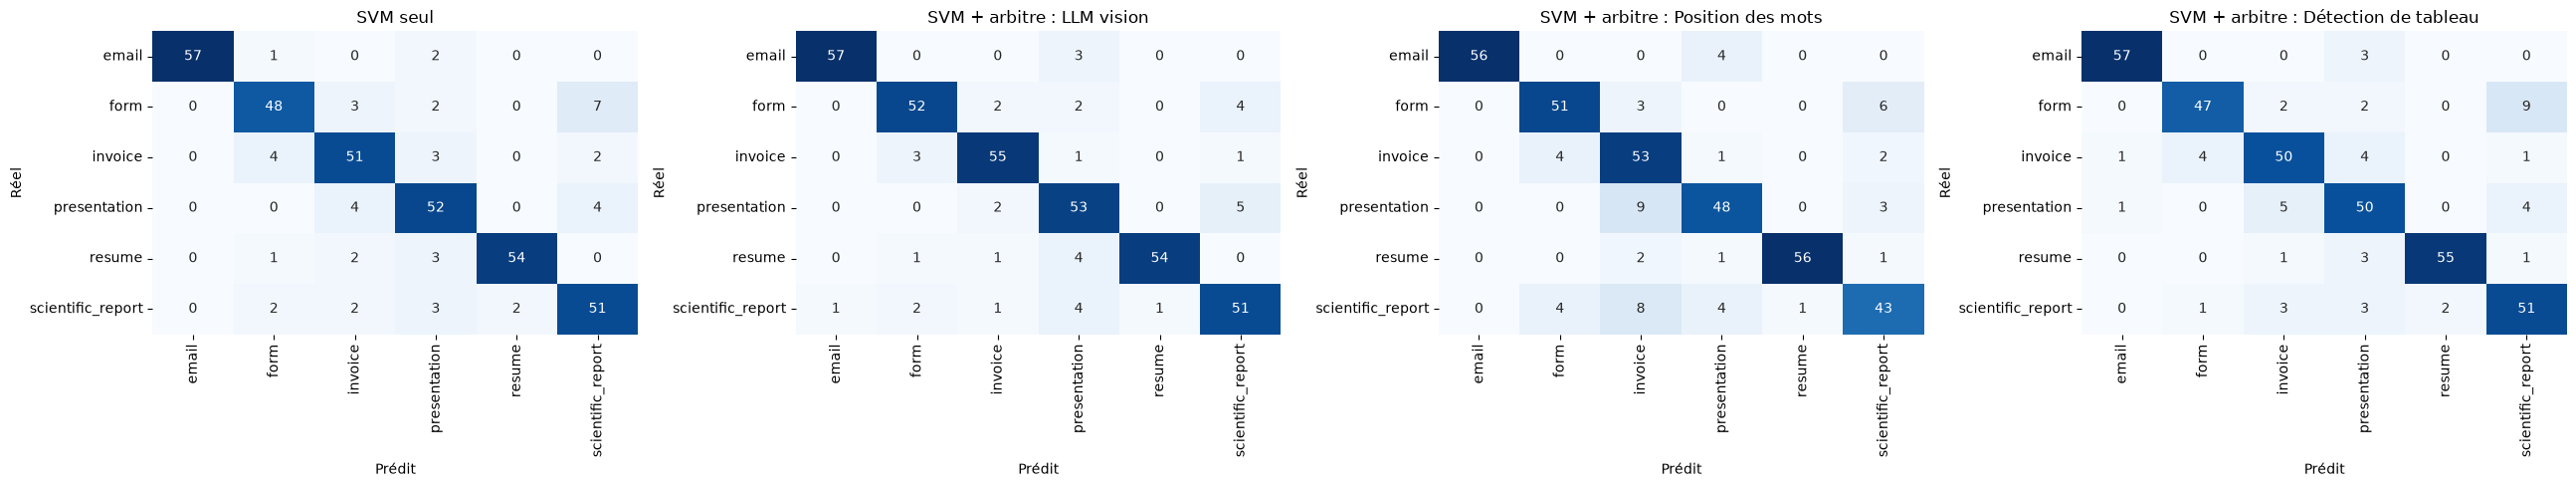

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(26, 5))
for ax, (nom, prediction) in zip(axes, [("SVM seul", prediction_svm), *choix.items()]):
    matrice = pd.crosstab(y_test, prediction, rownames=["Réel"], colnames=["Prédit"])
    sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(nom if nom == "SVM seul" else f"SVM + arbitre : {nom}")
plt.tight_layout()
plt.show()

## 4. Pourquoi deux arbitres échouent

Les paires de classes entre lesquelles le SVM hésite le plus :

In [8]:
paires = candidats[zone].apply(lambda doc: " / ".join(sorted([doc["top1"], doc["top2"]])), axis=1)
paires.value_counts().head(5)

invoice / presentation              19
form / scientific_report            10
presentation / scientific_report     8
form / invoice                       7
invoice / scientific_report          5
Name: count, dtype: int64

Moyenne des mesures par classe : un arbitre ne peut trancher que si les deux classes sont bien
différentes.

In [9]:
pd.read_csv(fichier_positions).groupby("label").mean(numeric_only=True).round(2)

,n_tokens,n_rows,tokens_par_ligne,alignement_colonnes,ratio_espace_blanc,aspect_bloc_texte
label,,,,,,
email,99.72,16.17,5.65,0.80,0.87,0.78
form,100.32,24.75,3.82,0.82,0.92,1.64
invoice,72.07,25.46,2.78,0.76,0.94,1.32
presentation,131.81,20.51,5.01,0.78,0.84,1.38
resume,256.25,37.00,6.62,0.96,0.78,1.36
scientific_report,149.97,25.81,5.15,0.83,0.87,1.44


In [10]:
pd.read_csv(fichier_tableau).groupby("label").mean(numeric_only=True).round(3)

,ratio_lignes_h,ratio_lignes_v,n_lignes_h,n_lignes_v
label,,,,
email,0.005,0.004,4.257,1.153
form,0.017,0.009,36.317,11.750
invoice,0.024,0.019,30.440,17.973
presentation,0.024,0.023,19.650,8.277
resume,0.006,0.002,16.873,2.590
scientific_report,0.014,0.011,15.800,5.420


- Position des mots : `form`, `invoice` et `scientific_report` ont presque le même nombre de lignes
  (environ 25) et le même alignement.
- Détection de tableau : `form` et `invoice` ont tous les deux des tableaux, et le SVM hésite surtout
  entre `invoice` et `presentation`.

## 5. La détection de tableau sur une facture

Image en noir et blanc (Otsu), puis ouverture morphologique avec un trait long et fin : seules les
lignes continues restent, le texte disparaît.

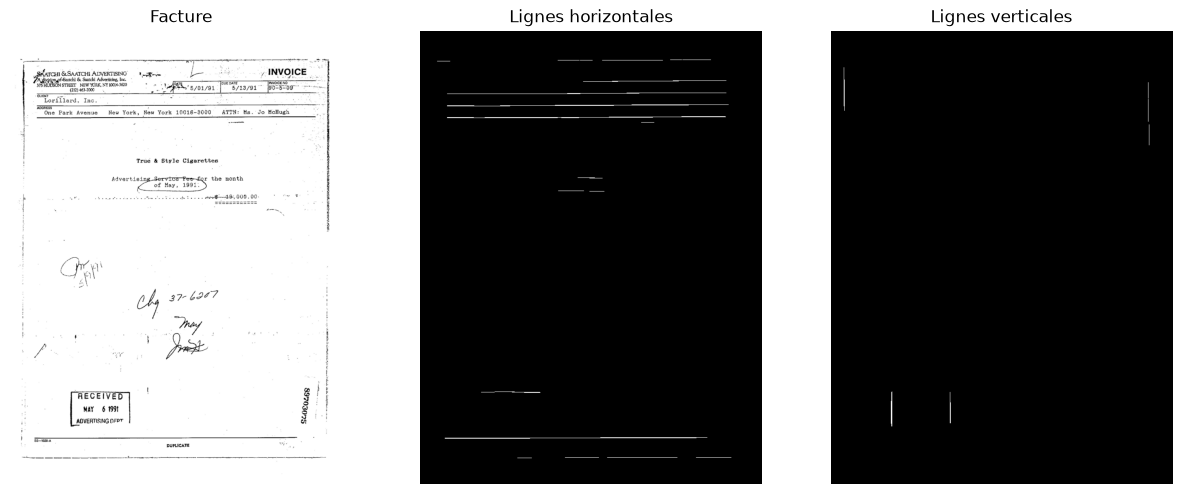

In [11]:
echantillon = pd.concat([train_df, test_df]).sort_index()  # remis dans l'ordre d'origine
image = cv2.imread("../" + echantillon.loc[echantillon["label"] == "invoice", "filepath"].iloc[0], cv2.IMREAD_GRAYSCALE)
_, encre = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
hauteur, largeur = encre.shape
lignes_h = cv2.morphologyEx(encre, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (max(20, largeur // 30), 1)))
lignes_v = cv2.morphologyEx(encre, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (1, max(20, hauteur // 30))))

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, img, titre in zip(axes, [image, lignes_h, lignes_v], ["Facture", "Lignes horizontales", "Lignes verticales"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(titre)
    ax.axis("off")
plt.show()